# Eje 6a — Black–Scholes: la fórmula (paso a paso)

Derivados Financieros — QUANt UCEMA

Black–Scholes–Merton da el precio de una **europea** en tiempo continuo (GBM + no arbitraje).
Acá desarmamos $d_1$, $d_2$ y la fórmula call/put, y la conectamos con `Codigo.pricing.opcion_europea_bs`.

| Notebook | Contenido |
|----------|-----------|
| **05** | Binomial CRR (camino discreto) |
| **06a** (este) | Fórmula BS a mano + librería |
| **06b** | Binomial vs BS y lectura vs mercado |
| **07** | Griegas |

Material legado: Clase 4 / `formuladeblacksholes`.

## 1) Setup

In [1]:
import math
import sys
from pathlib import Path

import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

ROOT = Path.cwd()
for p in [ROOT, *ROOT.parents]:
    if (p / "Codigo" / "pricing").exists():
        sys.path.insert(0, str(p))
        break

from Codigo.pricing import opcion_europea_bs, opcion_europea_bin
print("OK")

OK


## 2) Hipótesis (recordatorio)

- Subyacente: $dS = (r-q)S\,dt + \sigma S\,dW$ bajo la medida riesgo-neutral.
- Europea (sin ejercicio temprano), mercados perfectos, $\sigma$ y $r$ constantes.
- El precio es el valor esperado descontado del payoff bajo esa medida.

Definimos

$$
d_1 = \frac{\ln(S/K) + (r-q+\tfrac12\sigma^2)T}{\sigma\sqrt{T}}, \qquad
d_2 = d_1 - \sigma\sqrt{T}
$$

Interpretación rápida: $N(d_2)$ ≈ Prob* de terminar ITM (call); $N(d_1)$ entra en el término “delta” del call.

## 3) Parámetros y cálculo de $d_1$, $d_2$

In [2]:
tipo = "C"
S = 100.0
K = 100.0
T = 1.0
r = 0.05
sigma = 0.25
div = 0.0  # q en la notación de arriba

sqrtT = math.sqrt(T)
d1 = (math.log(S / K) + (r - div + 0.5 * sigma**2) * T) / (sigma * sqrtT)
d2 = d1 - sigma * sqrtT
print(f"d1={d1:.6f}  d2={d2:.6f}")
print(f"N(d1)={norm.cdf(d1):.6f}  N(d2)={norm.cdf(d2):.6f}")

d1=0.325000  d2=0.075000
N(d1)=0.627409  N(d2)=0.529893


## 4) Fórmula call / put

**Call:**
$$
C = e^{-qT} S\, N(d_1) - e^{-rT} K\, N(d_2)
$$

**Put:**
$$
P = e^{-rT} K\, N(-d_2) - e^{-qT} S\, N(-d_1)
$$

In [3]:
def bs_manual(tipo, S, K, T, r, sigma, div):
    sqrtT = math.sqrt(T)
    d1 = (math.log(S / K) + (r - div + 0.5 * sigma**2) * T) / (sigma * sqrtT)
    d2 = d1 - sigma * sqrtT
    if tipo == "C":
        return math.exp(-div * T) * S * norm.cdf(d1) - K * math.exp(-r * T) * norm.cdf(d2)
    if tipo == "P":
        return K * math.exp(-r * T) * norm.cdf(-d2) - math.exp(-div * T) * S * norm.cdf(-d1)
    raise ValueError("tipo debe ser C o P")

c_m = bs_manual("C", S, K, T, r, sigma, div)
p_m = bs_manual("P", S, K, T, r, sigma, div)
c_lib = opcion_europea_bs("C", S, K, T, r, sigma, div)
p_lib = opcion_europea_bs("P", S, K, T, r, sigma, div)
print(f"Call manual={c_m:.6f}  lib={c_lib:.6f}")
print(f"Put  manual={p_m:.6f}  lib={p_lib:.6f}")

Call manual=12.335999  lib=12.335999
Put  manual=7.458941  lib=7.458941


## 5) Paridad put–call (chequeo)

Para europeas con dividendos continuos:

$$
C - P = e^{-qT}S - e^{-rT}K
$$

In [4]:
lhs = c_lib - p_lib
rhs = math.exp(-div * T) * S - math.exp(-r * T) * K
print(f"C-P = {lhs:.6f}")
print(f"fwd = {rhs:.6f}")
print(f"|diff| = {abs(lhs - rhs):.2e}")

C-P = 4.877058
fwd = 4.877058
|diff| = 0.00e+00


## 6) Sensibilidad visual (preview de griegas)

Barrido de precio call vs $S$ y vs $\sigma$ — en el eje 7 cuantificamos $\Delta$, $\mathcal{V}$, etc.

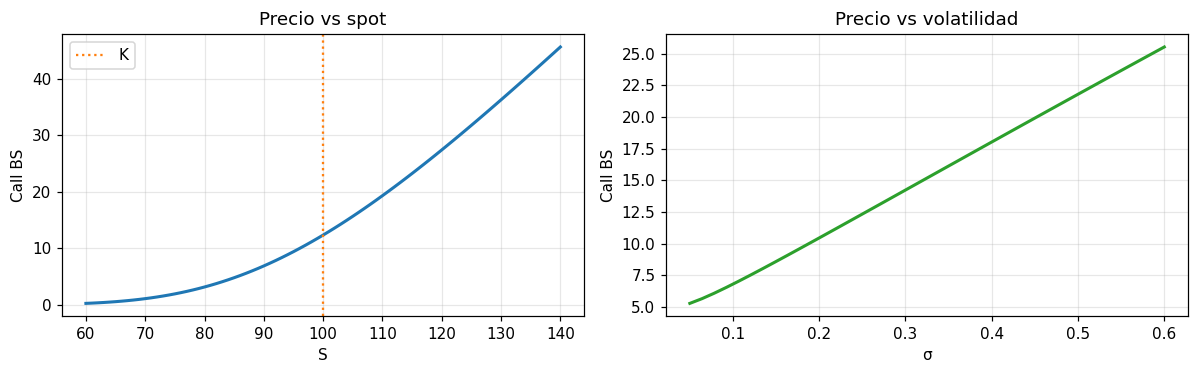

In [5]:
Ss = np.linspace(60, 140, 81)
Cs = [opcion_europea_bs("C", s, K, T, r, sigma, div) for s in Ss]
sigmas = np.linspace(0.05, 0.60, 40)
Cs_sig = [opcion_europea_bs("C", S, K, T, r, sig, div) for sig in sigmas]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), dpi=110)
ax[0].plot(Ss, Cs, lw=2)
ax[0].axvline(K, color="C1", ls=":", label="K")
ax[0].set_xlabel("S"); ax[0].set_ylabel("Call BS"); ax[0].set_title("Precio vs spot")
ax[0].legend(); ax[0].grid(True, alpha=0.3)

ax[1].plot(sigmas, Cs_sig, color="C2", lw=2)
ax[1].set_xlabel("σ"); ax[1].set_ylabel("Call BS"); ax[1].set_title("Precio vs volatilidad")
ax[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Resumen

- $d_1$, $d_2$ concentran moneyness, drift y vol; $N(\cdot)$ es la cdf normal.
- Call/put BS = valor presente del payoff esperado bajo la medida riesgo-neutral.
- Paridad put–call es un control rápido de implementación.
- **Ejercicio:** con $q=0.03$, recalculá call y put y verificá la paridad.
- **Siguiente:** **06b** — binomial vs BS y comparación con precios de mercado.